# 사이클 AE — 10/9 ~ 10/11 테스트 (펌프 14대)

**이 모델이 본 데이터**

| 구간 | 쓰임 |
|---|---|
| 09-10 ~ 10-04 | 기준선·학습·임계값 (건강일만) |
| 10-05 ~ 10-07 | 테스트 (README 의 평가 표) |
| 10-08 | `cycle_ae_test.ipynb` 에서 I7 하나만 |
| **10-09 ~ 10-11** | **처음 보는 날 — 이 노트북** (10-08 은 비교용으로 같이 본다) |

**그 사흘은 어떤 날이었나** (§1 에서 데이터로 확인)

- 10/9(금, 한글날) · 10/10(토): 평소처럼 생산 — 06~24시 자동운전
- 10/11(일): 자동운전 없음, 펌프 순환도 멈춤. 11시 무렵 잠깐 켠 기록만 — 점검으로 보인다

**볼 것**: ① 그날 펌프들이 어떤 상태였나 ② 펌프별 등급·알림 ③ 피처별로 평소와 얼마나 달랐나 ④ 10/11 점검을 모델이 어떻게 봤나 ⑤ 화면에 어떻게 표시할까

**임계값** — §2~§5 는 처음 돌렸을 때의 **예전 임계값**(calib 건강일 분위)으로 본다. 여기서 "정상 펌프도 알림이 많다" 를 찾았고,
그 뒤 임계값을 **날짜 단위**로 다시 잡고(`calibrate.py`, 신경망은 그대로) 같은 펌프·같은 이유 알림을 **운영일에 한 번**으로 바꿨다.
바뀐 결과는 **§8**.

---
## §0. 준비

In [1]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter

ROOT_DIR = os.path.abspath(os.getcwd())
for p in ["HDI_MODEL", "HDI_MODEL/cycle_ae", "HDI_MODEL/baseline"]:
    sys.path.insert(0, os.path.join(ROOT_DIR, p))
matplotlib.rcParams["font.family"] = "AppleGothic"
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)
warnings.simplefilter("ignore")

from new_pump_preprocessor import PumpSetup, PumpBaseline, run, add_baseline_features, load_settings, pump_tags
from extract_pump_cache import load_range, ORDER
import model as cae

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, CRITICAL = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
PLAIN = FuncFormatter(lambda v, _: f"{v:g}")


def style_ax(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)


S = load_settings()
ART = os.path.join(ROOT_DIR, "HDI_MODEL", "cycle_ae", "artifacts")
sc = cae.CycleScorer.load(ART)
NEWMETA = sc.meta                                                         # 지금 임계값 (날짜 단위, calibrate.py)
meta = {**NEWMETA, "thresholds": NEWMETA.get("thresholds_prev", NEWMETA["thresholds"])}   # §2~§5 는 예전 임계값
sc_old = cae.CycleScorer(sc.model, meta)
DAYS = ("2026-10-08", "2026-10-11")
NEW = pd.Timestamp("2026-10-09")
print("모델 학습:", meta["created"], "| 데이터셋 test_start:", meta["dataset"]["test_start"])

모델 학습: 2026-10-11T18:44:41 | 데이터셋 test_start: 2026-10-05


---
## §1. 그날 펌프들은 어떤 상태였나

10분마다 칠한다. 사출은 틱 수로는 순환보다 훨씬 적어서 다수결로 칠하면 안 보이므로 **우선순위**로:
그 10분 안에 자동 사출 틱이 있으면 자동 사출 → 수동 사출 틱이 있으면 수동 사출 → 순환 틱이 절반 넘으면 순환 대기 → 정지.

| 상태 | 정의 |
|---|---|
| 자동 사출 | `BuildUp=1` 이고 `Auto_Running=1` |
| 수동 사출 | `BuildUp=1` 인데 `Auto_Running=0` — 점검·시운전 |
| 순환 대기 | `BuildUp=0`, FT > 300 (사이클 사이 순환운전) |
| 정지 | 그 밖 (펌프 멈춤) |

In [2]:
STATE_NAMES = ["정지", "순환 대기", "자동 사출", "수동 사출"]
STATE_COLORS = ["#ece9e1", AQUA, BLUE, ORANGE]
RAW, STATE, TICKS = {}, {}, []
for p in ORDER:
    t = pump_tags(p, S)
    x = load_range(p, *DAYS)
    RAW[p] = x
    num = x.select_dtypes("number").ffill()
    bu = num[t["bu"]].fillna(0) > 0
    ar = num["Auto_Running"].fillna(0) > 0 if "Auto_Running" in num else pd.Series(True, index=num.index)
    ft = num[t["ft"]].fillna(0)
    st = np.select([bu & ar, bu & ~ar, ~bu & (ft > 300)], [2, 3, 1], 0)
    s = pd.Series(st, index=num.index)
    def _bin(v):
        if not len(v):
            return np.nan
        c = np.bincount(v, minlength=4)
        return 2 if c[2] else 3 if c[3] else 1 if c[1] > c[0] else 0
    STATE[p] = s.resample("10min").agg(_bin)
    for d, g in s.groupby(s.index.normalize()):
        cnt = np.bincount(g, minlength=4) / len(g) * 100
        on = (bu[g.index].astype(int).diff() > 0).sum()
        TICKS.append({"펌프": p, "날": d.strftime("%m-%d"), "틱": len(g), "켜짐": int(on),
                      **{f"{STATE_NAMES[i]}%": round(cnt[i], 1) for i in range(4)}})
TK = pd.DataFrame(TICKS)
TK.pivot(index="펌프", columns="날", values="켜짐").loc[ORDER]

날,10-08,10-09,10-10,10-11
펌프,,,,
P1,2869,2957,2790,2
I1,2869,2957,2790,2
P2,2963,3005,2841,0
I2,2963,3005,2841,0
P3,598,478,462,0
I3,598,478,462,0
P4,414,472,462,0
I4,414,472,462,0
P5,1028,1055,893,0


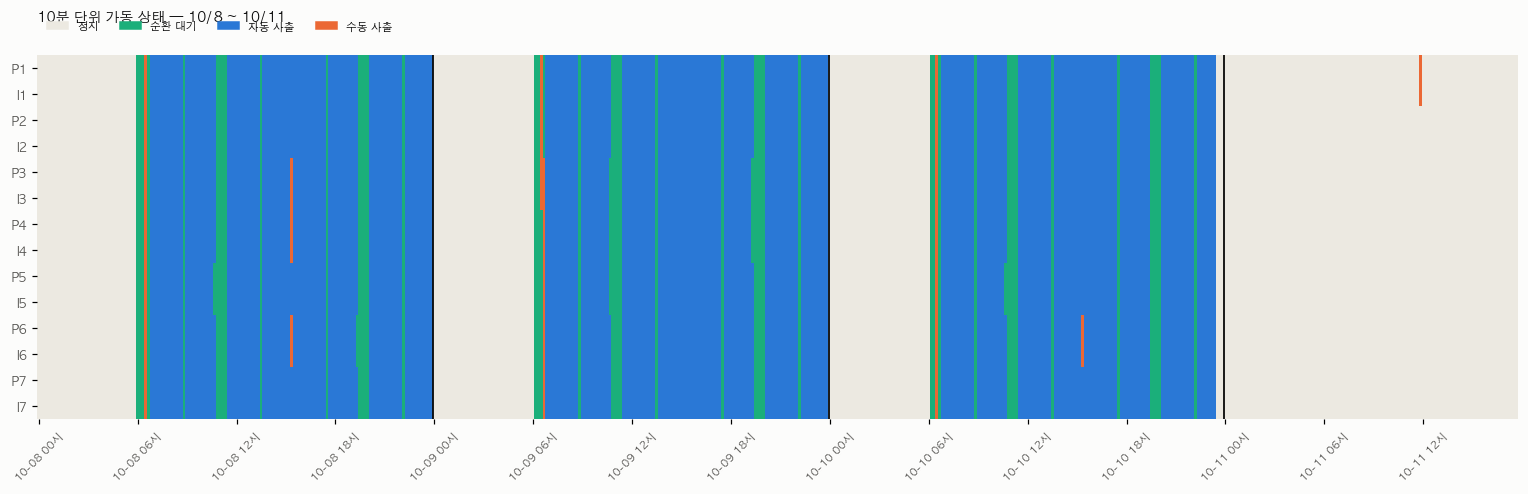

In [3]:
M = pd.DataFrame({p: STATE[p] for p in ORDER}).T
fig, ax = plt.subplots(figsize=(14, 4.6), facecolor=SURFACE)
cmap = ListedColormap(STATE_COLORS)
ax.imshow(M.to_numpy(float), aspect="auto", cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], 4), interpolation="nearest")
ax.set_yticks(range(len(M)), M.index, fontsize=8, color=INK2)
days = M.columns.normalize()
ticks = [i for i in range(len(M.columns)) if M.columns[i].hour % 6 == 0 and M.columns[i].minute == 0]
ax.set_xticks(ticks, [M.columns[i].strftime("%m-%d %H시") for i in ticks], fontsize=7, rotation=45, color=INK2)
for i in range(1, len(M.columns)):
    if days[i] != days[i - 1]:
        ax.axvline(i - 0.5, color=INK, lw=1.2)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[matplotlib.patches.Patch(color=c, label=n) for n, c in zip(STATE_NAMES, STATE_COLORS)],
          fontsize=7, frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, 1.12))
ax.set_title("10분 단위 가동 상태 — 10/8 ~ 10/11", loc="left", color=INK, fontsize=9, fontweight="bold", pad=22)
fig.tight_layout(); plt.show()

**읽기** — 아래 결과를 보고 쓴다. 날마다 "켜짐" 횟수(위 표)와 지도의 색으로:

- **10/9(한글날)·10/10(토)는 10/8 과 같은 생산일** — 06:50 전후 시작, 점심·저녁 쉬는 시간 외에는 자동 사출. 사이클 수도 10/8 과 비슷
- **10/11(일)은 하루 종일 정지.** P1·I1 만 11:56 에 1분쯤 켜서 **수동으로 2번 사출**(자동운전 0), 14:26 에 잠깐 순환. 나머지 12대는 아무것도 안 돌았다

---
## §2. 전처리 → 채점 → 등급·알림

- 전처리기 `run()` 으로 사이클을 만들고, 기준선 피처를 붙이고, `CycleScorer.score` 로 사이클 등급을 매긴다
- **알람·정지 플래그가 붙은 사이클도 채점은 한다** — 학습·운영 판정에서는 빼는 사이클이지만, 점검 때 모델이 무엇을 보는지 확인하려고
- 펌프 등급·알림(`WindowTracker`)은 운영과 같게 **플래그 없는 사이클만**으로 돌린다

In [4]:
t0 = time.time()
parts = []
for p in ORDER:
    stp = PumpSetup(p, S, allow_unverified=True)
    bs = PumpBaseline.load(os.path.join(ROOT_DIR, "HDI_MODEL", "baseline", f"{p}.json"))
    _, cy, _ = run(RAW[p], stp, bs, collect_ticks=False)
    if cy.empty:
        continue
    cy = add_baseline_features(cy[cy.FT > 0], bs)
    parts.append(sc_old.score(cy.assign(pump=p, material=bs.material)))
ALL = pd.concat(parts, ignore_index=True)
ALL["day"] = ALL.t_start.dt.strftime("%m-%d")
ALL["manual"] = ALL.flag_stopped & ~ALL.flag_alarm
OPS = cae.window_levels(ALL[~ALL.flag_any & ALL.in_scope].copy(), meta)          # 운영 판정 (플래그 없는 사이클)
print(f"사이클 {len(ALL):,}개 ({time.time() - t0:.0f}s) | 플래그 {ALL.flag_any.sum():,} (수동·정지 {ALL.flag_stopped.sum():,}, 알람 {ALL.flag_alarm.sum():,}) "
      f"| 범위 밖 {(~ALL.in_scope).sum():,}")

사이클 68,047개 (186s) | 플래그 292 (수동·정지 284, 알람 10) | 범위 밖 201


---
## §3. 펌프별

### 3-1. 날짜별 요약

정상 날의 기대값: 사이클 주의 ≈ 1%, 알림 ≈ 0.3%, 사람에게 가는 알림 펌프당 하루 0~1회 (학습 때 calib 기준).

In [5]:
def day_table(df):
    rows = []
    for (p, d), g in df.groupby(["pump", "day"]):
        nt = g[g.notify]
        rows.append({"펌프": p, "날": d, "사이클": len(g), "주의%": round((g.level != "정상").mean() * 100, 1),
                     "알림%": round((g.level == "알림").mean() * 100, 1),
                     "펌프 창 알림%": round((g.pump_level == "알림").mean() * 100, 1), "알림 횟수": int(len(nt)),
                     "알림 이유": "; ".join(f"{t:%H:%M} {r}" for t, r in zip(nt.t_start, nt.notify_reason))})
    return pd.DataFrame(rows)


DT = day_table(OPS)
piv = DT.pivot(index="펌프", columns="날", values=["주의%", "알림%", "알림 횟수"]).loc[ORDER]
piv

주의%               알림%             알림 횟수            
날  10-08 10-09 10-10 10-08 10-09 10-10 10-08 10-09 10-10
펌프                                                      
P1   1.2   1.0   2.8   0.4   0.2   1.0   1.0   0.0   1.0
I1  25.8   1.5   1.4  23.8   0.9   0.5   1.0   0.0   0.0
P2  54.7  48.1  40.2  29.5  25.3  22.5   1.0   1.0   1.0
I2  16.6   0.8   6.1  10.0   0.1   1.7   1.0   0.0   0.0
P3   1.0   1.1   1.3   0.3   0.4   0.0   0.0   0.0   0.0
I3   1.7   1.3   7.0   0.7   0.6   4.6   1.0   0.0   1.0
P4   1.0   1.3   4.5   0.3   1.1   3.1   1.0   1.0   1.0
I4   0.8   1.8   1.3   0.3   0.7   0.2   0.0   1.0   1.0
P5   2.9   2.1   3.5   0.8   0.9   0.8   1.0   1.0   1.0
I5   0.9   0.7   0.6   0.1   0.0   0.2   0.0   1.0   1.0
P6   0.0   2.8   2.0   0.0   0.9   0.3   1.0   1.0   1.0
I6  62.4  69.0  58.1  57.1  35.7  44.8   1.0   1.0   1.0
P7   1.6   1.4   1.6   0.3   0.3   0.4   1.0   1.0   1.0
I7  10.9  80.5  67.5   4.2  62.1  54.1   1.0   1.0   1.0

In [6]:
# 알림이 나간 것만
DT[DT["알림 횟수"] > 0].sort_values(["날", "펌프"])[["날", "펌프", "사이클", "주의%", "알림%", "알림 횟수", "알림 이유"]].reset_index(drop=True)

,날,펌프,사이클,주의%,알림%,알림 횟수,알림 이유
0,10-08,I1,2799,25.8,23.8,1,11:33 P0 높음
1,10-08,I2,2897,16.6,10.0,1,15:34 r_phys 높음
2,10-08,I3,593,1.7,0.7,1,13:56 P0 높음
3,10-08,I6,452,62.4,57.1,1,07:25 r_phys 낮음
4,10-08,I7,3081,10.9,4.2,1,16:23 r_phys 낮음
5,10-08,P1,2850,1.2,0.4,1,06:54 P0 높음
6,10-08,P2,2919,54.7,29.5,1,06:55 P0 높음
7,10-08,P4,397,1.0,0.3,1,07:54 ft_cv 낮음
8,10-08,P5,1008,2.9,0.8,1,15:55 r_phys 낮음
9,10-08,P6,454,0.0,0.0,1,07:25 t_self 높음


**읽기**

- 주의·알림 **비율**이 몰린 펌프는 넷 — **P2·I2**(같은 헤드 HD1-2), **I6**, **I7** (+ 10/8 의 I1). 넷 다 "새 이상" 이 아니라
  **이미 알던 상태가 이어진 것**이다 (§4)
- 알림 **횟수**는 펌프마다 하루 최대 1번 — 운영일 알림 기억(§8) 때문. 처음 돌렸을 땐 이 기억이 없어 P2 가 쉬는 시간 뒤
  재가동마다 다시 울려 하루 4~7번이었다
- 나머지 10대도 거의 날마다 한 번씩 울린다 — 학습 때 기대(펌프당 하루 0.34회)보다 많다. §5 에서 원인을 본다

### 3-2. 시간대별 — 펌프 × 1시간, 사이클 주의 이상 비율

빨간 테두리 = 그 시간에 사람에게 알림이 나감.

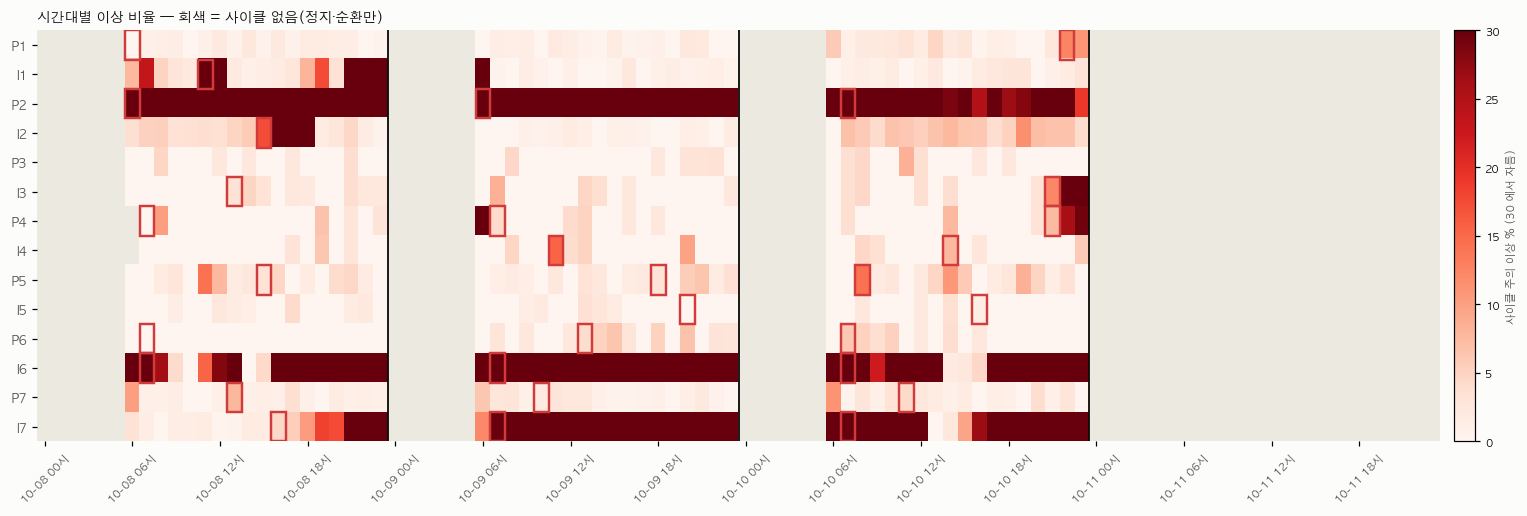

In [7]:
OPS["hour"] = OPS.t_start.dt.floor("h")
H = OPS.groupby(["pump", "hour"])["level"].apply(lambda s: (s != "정상").mean() * 100).unstack("hour").reindex(ORDER)
full = pd.date_range(DAYS[0], pd.Timestamp(DAYS[1]) + pd.Timedelta(hours=23), freq="h")
H = H.reindex(columns=full)
fig, ax = plt.subplots(figsize=(14, 4.8), facecolor=SURFACE)
cm = matplotlib.colormaps["Reds"].copy(); cm.set_bad("#ece9e1")
im = ax.imshow(np.ma.masked_invalid(H.to_numpy(float)), aspect="auto", cmap=cm, vmin=0, vmax=30, interpolation="nearest")
ax.set_yticks(range(len(H)), H.index, fontsize=8, color=INK2)
ticks = [i for i, c in enumerate(H.columns) if c.hour % 6 == 0]
ax.set_xticks(ticks, [H.columns[i].strftime("%m-%d %H시") for i in ticks], fontsize=7, rotation=45, color=INK2)
for i, c in enumerate(H.columns):
    if c.hour == 0 and i:
        ax.axvline(i - 0.5, color=INK, lw=1.2)
for _, r in OPS[OPS.notify].iterrows():
    j = H.columns.get_loc(r.hour); k = ORDER.index(r.pump)
    ax.add_patch(plt.Rectangle((j - 0.5, k - 0.5), 1, 1, fill=False, ec=CRITICAL, lw=1.6))
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.015, pad=0.01); cb.ax.tick_params(labelsize=7)
cb.set_label("사이클 주의 이상 % (30 에서 자름)", fontsize=7, color=INK2)
ax.set_title("시간대별 이상 비율 — 회색 = 사이클 없음(정지·순환만)", loc="left", color=INK, fontsize=9, fontweight="bold")
fig.tight_layout(); plt.show()

---
## §4. 피처별 — 평소 대비 얼마나 치우쳤나

각 피처의 **표준화 값 z**(그 묶음의 학습 구간 중앙값 0, 평소 흔들림 1 칸) 를 펌프 × 날마다 중앙값으로.
학습 때 정상이면 0 근처. ±1 을 넘으면 그날 하루 내내 평소와 다른 쪽에 있었다는 뜻이다.

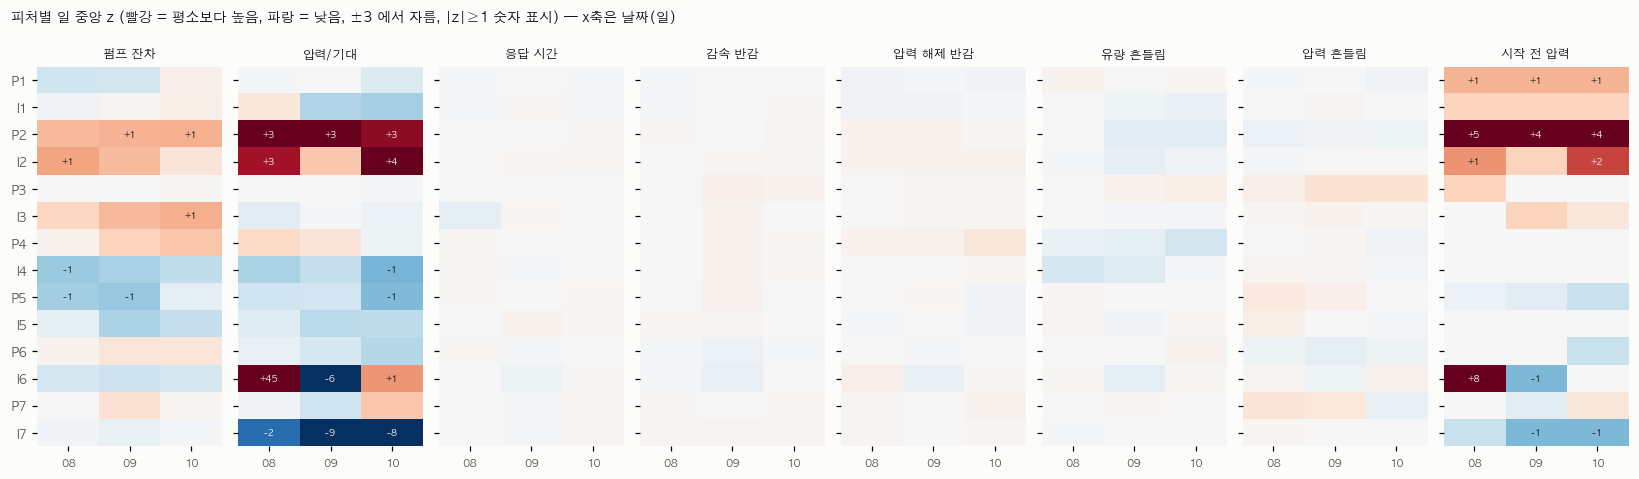

In [8]:
F = meta["features"]
Z = []
for k, g in OPS.groupby("group"):
    s = meta["stats"][k]
    z = pd.DataFrame({f: (g[f] - s["med"][f]) / s["scale"][f] for f in F})
    z["pump"], z["day"] = g.pump.values, g.day.values
    Z.append(z)
Z = pd.concat(Z)
ZD = Z.groupby(["pump", "day"])[F].median()
day_list = sorted(OPS.day.unique())
fig, axes = plt.subplots(1, len(F), figsize=(15, 4.4), facecolor=SURFACE, sharey=True)
norm = TwoSlopeNorm(vmin=-3, vcenter=0, vmax=3)
for ax, f in zip(axes, F):
    m = ZD[f].unstack("day").reindex(index=ORDER, columns=day_list)
    ax.imshow(m.to_numpy(float), aspect="auto", cmap="RdBu_r", norm=norm, interpolation="nearest")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            if np.isfinite(v) and abs(v) >= 1:
                ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 2 else INK)
    ax.set_xticks(range(len(day_list)), [d[3:] for d in day_list], fontsize=7, color=INK2)
    ax.set_title(cae.FEATURE_KO.get(f, f), fontsize=8, color=INK)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_yticks(range(len(ORDER)), ORDER, fontsize=8, color=INK2)
fig.suptitle("피처별 일 중앙 z (빨강 = 평소보다 높음, 파랑 = 낮음, ±3 에서 자름, |z|≥1 숫자 표시) — x축은 날짜(일)",
             x=0.01, ha="left", fontsize=9, color=INK)
fig.tight_layout(); plt.show()

In [9]:
# 날마다 어느 피처가 경보 이유로 많이 나왔나 (주의 이상 사이클)
why = OPS[OPS.level != "정상"].assign(이유=lambda d: d.top_feature.map(cae.FEATURE_KO) + " " + d.top_dir)
why.groupby(["day", "이유"]).size().unstack("day").fillna(0).astype(int).sort_values(day_list[-2] if len(day_list) > 1 else day_list[0], ascending=False).head(12)

day,10-08,10-09,10-10
이유,,,
압력/기대 낮음,692,2772,2252
시작 전 압력 높음,1538,1180,874
펌프 잔차 높음,244,167,314
압력/기대 높음,706,86,267
감속 반감 높음,99,68,91
압력 해제 반감 높음,55,39,54
압력 흔들림 낮음,19,31,33
압력 흔들림 높음,31,28,16
펌프 잔차 낮음,31,22,40


**읽기 — 피처로 보면 원인이 갈린다**

| 펌프 | 피처 | 해석 |
|---|---|---|
| **P2 · I2** | 압력/기대 +3~4, 시작 전 압력 +2~5 — **둘 다 같은 방향** | 10/6 부터 이어진 배관 저항 증가. 같은 헤드(HD1-2)의 폴리올·ISO 가 같이 올랐으니 **펌프가 아니라 헤드(노즐·믹싱) 쪽** 일 가능성이 크다 |
| **I7** | 압력/기대 −2 → −9 → −8 | 9/23 전·10/6 에 보던 저항 드리프트가 더 크게 재발 |
| **I6** | 압력/기대 +45 → −6 → +1 | 압력이 몇 단계 사이를 크게 오간다 (baseline/README) |
| P5 · I4 | 펌프 잔차·압력/기대 −1 | 약한 치우침 — 지켜볼 정도 |

다른 피처(응답 시간, 반감 시각, 흔들림)는 14대 모두 0 근처 — 펌프·모터 쪽 이상은 없다.

### 4-1. 알림이 나간 펌프 들여다보기

알림이 가장 많았던 펌프들의 주요 피처를 시간순으로. 회색 띠 = 학습 때 정상 범위(±zq, 그 피처의 정상 한계).

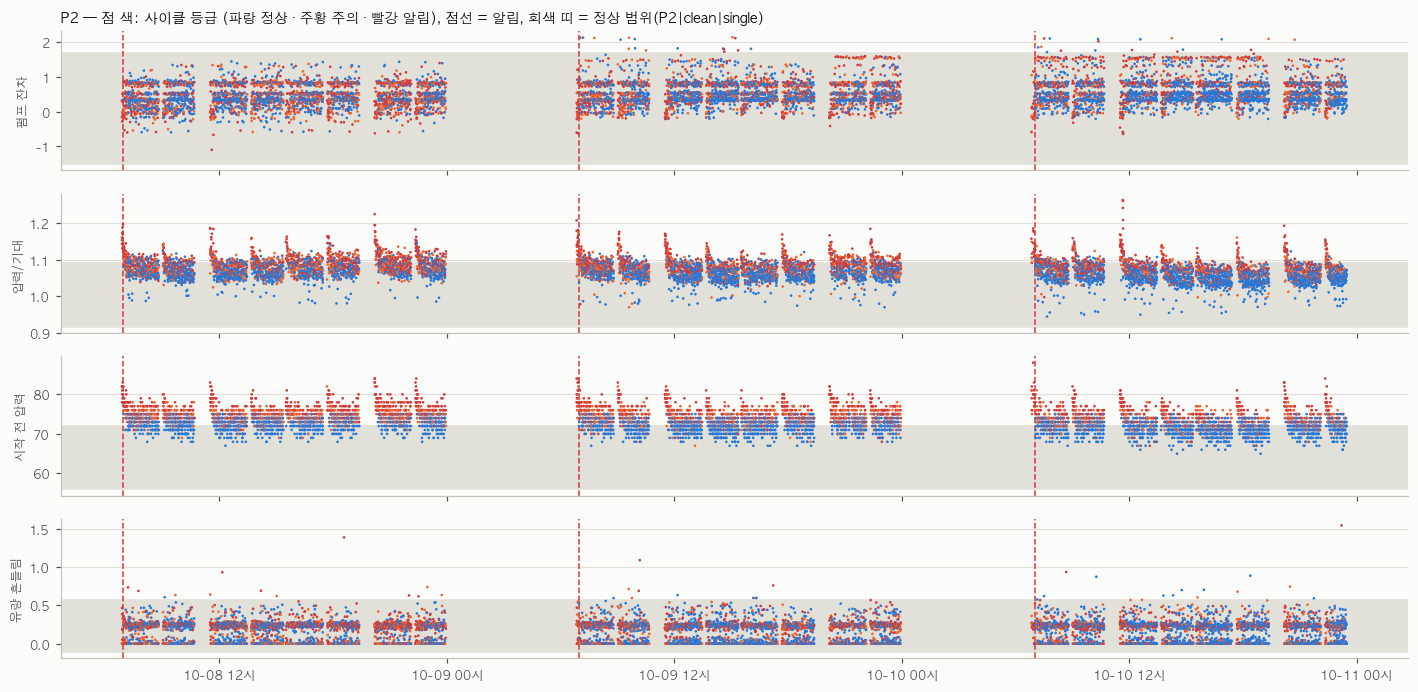

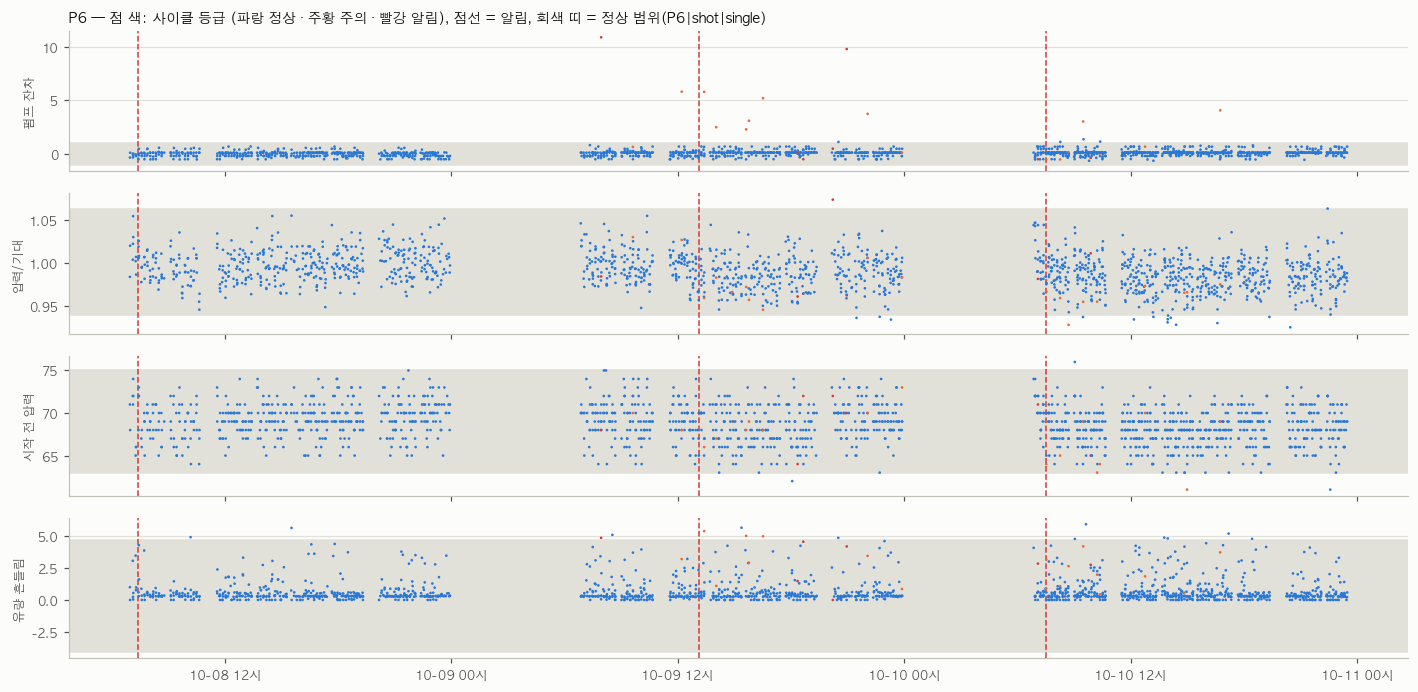

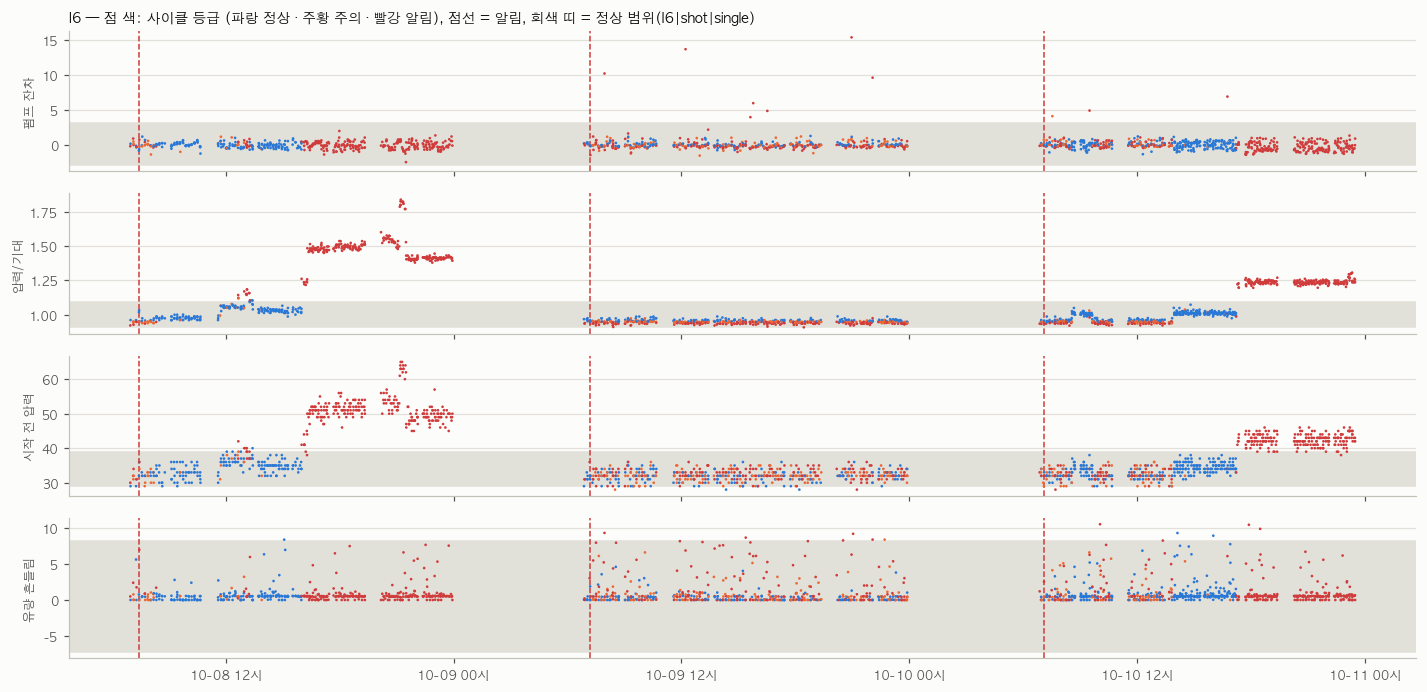

In [10]:
top = OPS[OPS.notify].pump.value_counts().head(3).index.tolist() or OPS.groupby("pump").apply(lambda g: (g.level != "정상").mean()).nlargest(3).index.tolist()
for p in top:
    g = OPS[OPS.pump == p].sort_values("t_start")
    zz = Z[Z.pump == p].loc[g.index] if set(g.index) <= set(Z.index) else None
    fig, axes = plt.subplots(4, 1, figsize=(13, 6.4), sharex=True, facecolor=SURFACE)
    for ax, f in zip(axes, ["pump_resid", "r_phys", "P0", "ft_cv"]):
        ax.scatter(g.t_start, g[f], s=3, lw=0, color=[{"정상": BLUE, "주의": ORANGE, "알림": CRITICAL}[l] for l in g.level], zorder=3)
        k = g.group.mode().iloc[0]; s = meta["stats"][k]
        lo, hi = s["med"][f] - s["zq"][f] * s["scale"][f], s["med"][f] + s["zq"][f] * s["scale"][f]
        ax.axhspan(lo, hi, color=GRID, zorder=0)
        style_ax(ax); ax.set_ylabel(cae.FEATURE_KO[f], fontsize=8, color=INK2)
        for t in g[g.notify].t_start:
            ax.axvline(t, color=CRITICAL, lw=1, ls="--")
    axes[0].set_title(f"{p} — 점 색: 사이클 등급 (파랑 정상 · 주황 주의 · 빨강 알림), 점선 = 알림, 회색 띠 = 정상 범위({k})",
                      loc="left", fontsize=9, color=INK, fontweight="bold")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H시"))
    fig.tight_layout(); plt.show()

---
## §5. 정상 펌프도 알림이 많은 이유 — 그리고 고칠 방법

알려진 지속 상태 펌프(P2·I2·I6·I7)를 뺀 10대가 새 날에 받은 알림을 본다. 학습 때 기대는 펌프당 하루 약 0.34회.

In [11]:
KNOWN = ["P2", "I2", "I6", "I7"]
norm = OPS[~OPS.pump.isin(KNOWN)].copy()
nd = norm[norm.day.isin(["10-08", "10-09", "10-10"])]
print(f"정상 펌프 10대 × 3일 알림 {int(nd.notify.sum())}건 = 펌프당 하루 {nd.notify.sum() / 30:.2f}회 (학습 때 기대 0.34)")

# ① 점수 분포가 학습 때보다 올라갔나
SC = pd.read_pickle(os.path.join(ROOT_DIR, "cache", "pump_dataset", "scores.pkl.xz"), compression="xz")
SC = cae.add_levels(SC.drop(columns=["alarm_ae", "alarm_z", "alarm", "alert", "level"]), meta["thresholds"])   # 예전 임계값으로
cal = SC[(SC.role == "calib") & SC.in_scope & ~SC.pump.isin(KNOWN)]
cmp = pd.DataFrame({"calib (학습 때 건강일)": [(cal.level != "정상").mean() * 100, (cal.level == "알림").mean() * 100, cal.score.median()],
                    "10/8~10 (새 날)": [(nd.level != "정상").mean() * 100, (nd.level == "알림").mean() * 100, nd.score.median()]},
                   index=["사이클 주의 이상 %", "사이클 알림 %", "패턴 점수 중앙"]).round(3)
display(cmp)

# ② 재가동 직후 때문인가 — 직전 사이클과 30분 넘게 떨어지면 재가동
norm = norm.sort_values(["pump", "t_start"])
gap = norm.groupby("pump").t_start.diff().dt.total_seconds() / 60
seg = (gap.isna() | (gap > 30)).groupby(norm.pump).cumsum()
norm["재가동 후 분"] = (norm.t_start - norm.groupby([norm.pump, seg]).t_start.transform("min")).dt.total_seconds() / 60
b = pd.cut(norm["재가동 후 분"], [0, 5, 10, 15, 30, 60, 1e4], include_lowest=True, labels=["0~5", "5~10", "10~15", "15~30", "30~60", "60~"])
display(norm.groupby(b).agg(사이클=("level", "size"), 주의=("level", lambda s: round((s != "정상").mean() * 100, 1)),
                            알림=("notify", "sum")).T)

# ③ 알림은 창 중앙값이 임계를 얼마나 넘어서 났나
nt = norm[norm.notify].copy()
nt["점수 중앙/임계"] = nt.score_med / nt.group.map({k: v["alert"]["roll"] for k, v in meta["thresholds"].items()})
nt["수준 중앙/임계"] = nt.zmax_med / nt.group.map({k: v["alert"]["zmax_roll"] for k, v in meta["thresholds"].items()})
nt[["점수 중앙/임계", "수준 중앙/임계"]].describe().loc[["count", "25%", "50%", "75%", "max"]].round(2)

정상 펌프 10대 × 3일 알림 21건 = 펌프당 하루 0.70회 (학습 때 기대 0.34)


,calib (학습 때 건강일),10/8~10 (새 날)
사이클 주의 이상 %,1.006,3.380
사이클 알림 %,0.274,2.214
패턴 점수 중앙,0.148,0.175


재가동 후 분,0~5,5~10,10~15,15~30,30~60,60~
사이클,679.0,624.0,680.0,2072.0,4103.0,31276.0
주의,8.4,1.8,1.9,2.6,4.3,3.3
알림,2.0,1.0,0.0,3.0,3.0,12.0


,점수 중앙/임계,수준 중앙/임계
count,21.00,21.00
25%,1.04,0.64
50%,1.09,0.87
75%,1.20,0.98
max,1.69,3.41


**읽기**

- **새 날엔 정상 펌프도 점수가 조금 올라가 있다** — 사이클 주의 이상이 학습 때 약 1% → 새 날 3% 대. 학습(~10/4) 뒤 1~2주 지나며 생긴
  자잘한 변화(재료 로트, 온도, 배관 상태)가 쌓인 것으로, 데이터 4주로 정한 임계값의 한계다
- **재가동 직후가 원인은 아니다** — 처음 10분의 주의 비율이 조금 높을 뿐, 알림 대부분은 재가동 후 15분이 지나서 났다
- **알림 대부분이 창 중앙값이 임계를 겨우 넘어서(1.0~1.15 배) 났다** — 경계선 근처에서 울린 것

### 5-1. 창 알림 임계에 여유를 주면

창(10사이클) **알림** 임계에만 배수를 곱해 본다(주의는 그대로). 정상 펌프의 새 날 알림과, 알려진 이벤트를 잡는지 같이 본다.

In [12]:
from dataset import EVAL_EVENTS


def with_margin(mult):
    return {"roll": meta["roll"], "thresholds": {k: {**v, "alert": {**v["alert"], "roll": v["alert"]["roll"] * mult,
                                                                       "zmax_roll": v["alert"]["zmax_roll"] * mult}}
                                                for k, v in meta["thresholds"].items()}}


hist = SC[SC.in_scope & (~SC.excluded | SC.event.ne(""))][["pump", "group", "t_start", "score", "zmax", "top_feature", "top_dir",
                                                         "level", "event", "role", "day"]]
new = ALL[~ALL.flag_any & ALL.in_scope & ~ALL.pump.isin(KNOWN)]
rows = []
for mult in [1.0, 1.25, 1.5]:
    m = with_margin(mult)
    o = cae.window_levels(new.copy(), m)
    h = cae.window_levels(hist.copy(), m)
    c = h[h.role == "calib"]
    r = {"창 알림 임계": f"× {mult}", "새 날 정상 펌프 알림/펌프·일": round(o.notify.sum() / 30, 2),
         "학습 calib 알림/펌프·일": round(c.notify.sum() / c.groupby(["pump", "day"]).ngroups, 2)}
    for p, a, b_, name in EVAL_EVENTS[:-1]:
        g = h[(h.pump == p) & (h.event == name)]
        f = g[g.notify].t_start.min()
        r[name.split(" (")[0]] = f"{(g.pump_level == '알림').mean() * 100:.0f}%" + ("" if pd.isna(f) else f" · 첫 알림 {f:%m-%d %H:%M}")
    rows.append(r)
MG = pd.DataFrame(rows).set_index("창 알림 임계").T
MG

창 알림 임계,× 1.0,× 1.25,× 1.5
새 날 정상 펌프 알림/펌프·일,0.7,0.27,0.2
학습 calib 알림/펌프·일,0.31,0.03,0.0
P7 유량계 전조,50% · 첫 알림 09-16 22:25,46% · 첫 알림 09-16 22:25,41% · 첫 알림 09-16 22:27
P7 유량계 고장,97% · 첫 알림 09-17 06:56,97% · 첫 알림 09-17 06:56,97% · 첫 알림 09-17 06:56
I1 노즐 저항 감소,98% · 첫 알림 09-29 06:54,98% · 첫 알림 09-29 06:54,98% · 첫 알림 09-29 06:54
I1 노즐 저항 증가,92%,91%,91%
P2 배관 저항 +7%,98% · 첫 알림 10-06 06:56,93% · 첫 알림 10-06 06:56,78% · 첫 알림 10-06 06:56
I7 저항 드리프트,83% · 첫 알림 09-10 06:56,82% · 첫 알림 09-10 06:56,81% · 첫 알림 09-10 06:56
I7 저항 드리프트 재발,60% · 첫 알림 10-05 21:26,59% · 첫 알림 10-05 21:59,58% · 첫 알림 10-05 22:20


**읽기**

- **× 1.25** 면 정상 펌프 새 날 알림이 기대 수준(펌프당 하루 0.3~0.4회)으로 내려오고, 알려진 이벤트는 **첫 알림 시각까지 그대로** 잡는다
  (I7 드리프트 재발만 30분쯤 늦다. I1 저항 증가는 그 구간 전에 이미 알림 상태라 새 알림 없이 91% 알림 유지)
- × 1.5 부터는 P2 배관 저항 +7% 같은 작은 변화의 창 알림 비율이 떨어지기 시작한다
- 배수를 곱하는 건 임시방편이라, 대신 **임계값을 날짜 단위로 다시 잡았다** — 정상 날 하루하루의 분위값 중앙값 + 4·MAD
  (`calibrate.py`). 날마다 흔들리는 폭이 임계값에 들어가고, 배수 없이 비슷한 효과를 낸다 → §8

---
## §6. 10/11 — 점검 날

자동운전이 없던 날. 무엇이 돌았고, 모델은 뭐라고 했나.

In [13]:
d11 = TK[TK["날"] == "10-11"].set_index("펌프").loc[ORDER]
print("10/11 상태 비율 (%)"); display(d11[["틱", "켜짐", "정지%", "순환 대기%", "자동 사출%", "수동 사출%"]])
c11 = ALL[ALL.day == "10-11"]
print(f"10/11 사이클 {len(c11)}개 — 수동(자동운전 0) {int(c11.flag_stopped.sum())}, 알람 {int(c11.flag_alarm.sum())}")
c11[["pump", "t_start", "SV_class", "Hz", "steady_src", "n_hz_levels", "FT", "PT", "FT_SV", "pump_resid", "r_phys",
     "flag_stopped", "flag_alarm", "in_scope", "score", "zmax", "level", "top_feature", "top_dir"]].round(3)

10/11 상태 비율 (%)


,틱,켜짐,정지%,순환 대기%,자동 사출%,수동 사출%
펌프,,,,,,
P1,97745,2,99.8,0.1,0.0,0.0
I1,102575,2,99.8,0.1,0.0,0.0
P2,101332,0,100.0,0.0,0.0,0.0
I2,95448,0,100.0,0.0,0.0,0.0
P3,103581,0,100.0,0.0,0.0,0.0
I3,101147,0,100.0,0.0,0.0,0.0
P4,102845,0,100.0,0.0,0.0,0.0
I4,104880,0,100.0,0.0,0.0,0.0
P5,94788,0,100.0,0.0,0.0,0.0


10/11 사이클 4개 — 수동(자동운전 0) 4, 알람 0


,pump,t_start,SV_class,Hz,steady_src,n_hz_levels,FT,PT,FT_SV,pump_resid,r_phys,flag_stopped,flag_alarm,in_scope,score,zmax,level,top_feature,top_dir
8607,P1,2026-10-11 11:56:38.402270,2980.0,4733.0,clean,1,2950.0,152.0,0.990,-0.440,1.029,True,False,True,1.956,1.574,알림,P0,높음
8608,P1,2026-10-11 11:56:57.150174,2980.0,4733.0,clean,1,2965.0,149.0,0.995,0.066,1.009,True,False,True,0.075,0.562,정상,P0,높음
17216,I1,2026-10-11 11:56:38.402270,1300.0,3773.0,clean,1,1275.0,98.0,0.981,-0.406,1.010,True,False,True,0.201,0.800,정상,P0,높음
17217,I1,2026-10-11 11:56:57.150174,1300.0,3773.0,clean,1,1268.0,98.0,0.975,-0.953,1.010,True,False,True,0.128,0.556,정상,t_self,낮음


10/11 에 움직인 펌프: ['P1', 'I1']


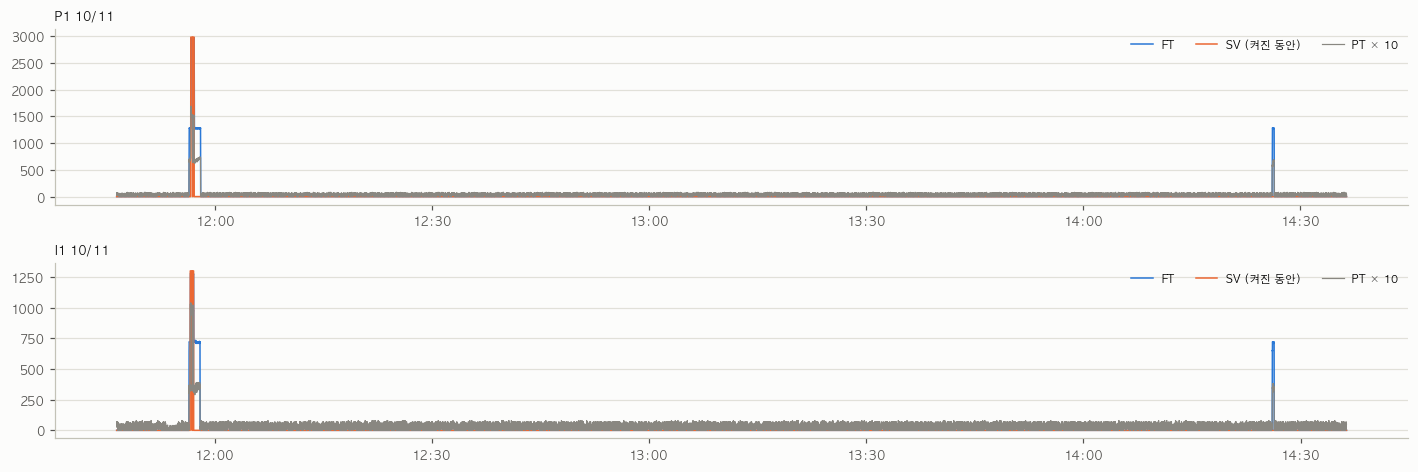

In [14]:
# 10/11 에 무언가 움직인 펌프의 원시 신호
moved = [p for p in ORDER if TK[(TK["펌프"] == p) & (TK["날"] == "10-11")][["켜짐"]].iloc[0, 0] > 0
         or TK[(TK["펌프"] == p) & (TK["날"] == "10-11")]["순환 대기%"].iloc[0] > 0.5]
print("10/11 에 움직인 펌프:", moved)
if moved:
    fig, axes = plt.subplots(len(moved), 1, figsize=(13, 1.9 * len(moved) + 0.6), facecolor=SURFACE, squeeze=False)
    for ax, p in zip(axes[:, 0], moved):
        t = pump_tags(p, S)
        x = RAW[p].select_dtypes("number").ffill()
        x = x[(x.index >= "2026-10-11")]
        act = x[(x[t["bu"]] > 0) | (x[t["ft"]] > 50)]
        if len(act):
            a, b = act.index.min() - pd.Timedelta(minutes=10), act.index.max() + pd.Timedelta(minutes=10)
            x = x[(x.index >= a) & (x.index <= b)]
        ax.plot(x.index, x[t["ft"]], color=BLUE, lw=1, label="FT")
        ax.plot(x.index, x[t["sv"]] * (x[t["bu"]] > 0), color=ORANGE, lw=1, label="SV (켜진 동안)")
        ax2v = x[t["pt"]].where(x[t["pt"]] < 32768)
        ax.plot(x.index, ax2v * 10, color=MUTED, lw=0.8, label="PT × 10")
        style_ax(ax); ax.legend(fontsize=7, frameon=False, loc="upper right", ncol=3)
        ax.set_title(f"{p} 10/11", loc="left", fontsize=8, color=INK, fontweight="bold")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    fig.tight_layout(); plt.show()

**읽기**

- 10/11 에 사이클이 나온 건 **P1·I1 의 수동 사출 2번(11:56)** 뿐이다. 자동운전 0 이라 플래그가 붙어 운영 판정에서는 빠진다
- 채점해 보면 FT/SV 0.98~0.995, 펌프 잔차 −1~0%, 압력/기대 1.01~1.03 — **펌프 자체는 정상**.
  P1 첫 사이클만 사이클 등급 "알림"(시작 전 압력 높음) — 하루 넘게 멈춰 있다가 첫 사출이라 배관 압력이 평소와 다른 것으로, 이상이 아니다
- → **수동·점검 사출에 알림을 띄우면 안 되는 이유**가 이것이다. 점수는 참고로 남기되 알림은 막는다

---
## §7. 화면에 어떻게 표시할까 — 제안

모델 등급(정상·주의·알림)은 **자동 운전 중 사이클**에만 의미가 있다. 그 밖의 시간은 "정상" 이 아니라 "판정 없음" 이고,
그 이유를 상태로 보여 줘야 한다 — 회색 "판정 없음" 하나로 뭉뚱그리면 "펌프가 멈춘 건지, 모델이 못 본 건지" 를 구분 못 한다.

| 화면 상태 | 조건 | 모델 판정 | 알림 |
|---|---|---|---|
| **정지** | 사이클도 순환도 없음 (FT ≈ 0) | 없음 | 없음 |
| **대기 순환** | 사출 없이 순환 Hz 로만 돎 | 없음 (순환 기준선은 추세용) | 없음 |
| **점검·수동** | 사출은 있는데 `Auto_Running = 0` | 점수는 계산해 **참고값**으로만 | 없음 — 재가동 첫 사이클처럼 평소와 다른 게 당연 |
| **판정 범위 밖** | 학습 사이클이 적은 묶음 (P4·I4 사출 중 등) | 없음 | 없음 |
| 정상 / 주의 / 알림 | 자동 운전 사이클 | 등급 | 알림만, 한 번 |

- 재가동하면 `WindowTracker` 가 30분 정지 뒤 창을 비우므로 점검 날 기록이 다음 근무로 넘어가지 않는다

**이번 테스트로 더 필요해진 것**

| 상황 | 지금 | 제안 |
|---|---|---|
| **알던 이상이 계속됨** (P2·I2 10/6~, I7 드리프트, I6) | 처음엔 쉬는 시간마다 다시 알림(P2 하루 4~7회) → **운영일에 한 번으로 바꿈**(§8) | 화면엔 **"지속 이상"** 으로 계속 표시, **담당자가 확인(인지)하면 다음 날부터도 멈춤**. 정비로 해결되면 확인 해제. 정비 없이 "새 정상" 이면 기준선 재학습 |
| **같은 헤드의 POL·ISO 가 같은 이유로 같이 알림** (P2·I2: 둘 다 압력/기대·시작 전 압력 높음) | 펌프 2개 따로 알림 | **헤드 1개 알림**으로 묶기 — "HD1-2 토출 저항 증가 (POL·ISO 동시)". 원인이 펌프가 아니라 헤드·노즐 쪽이라는 정보 자체가 진단이다 |
| 정상 펌프 경계선 알림 | 펌프당 하루 1.4회 | **날짜 단위 임계값으로 바꿈** → 0.37회 (§8) |
| 수동·점검 사출 (10/11) | 플래그 사이클이라 판정 제외 | "점검·수동" 상태로 표시, 점수는 참고값, 알림 없음 |
- 점검 사이클의 점수는 **정비 기록과 같이 남기면** 나중에 "정비 전후 펌프 잔차가 얼마나 바뀌었나" 를 보는 재료가 된다
- 백엔드 `PumpMonitor` 의 반환 형태로는: 정지·대기·점검·범위 밖 → `None`(판정 없음) 에 `state` 필드를 붙여 구분, 자동 운전 → 판정 dict

---
## §8. 적용 후 — 날짜 단위 임계값 + 운영일 알림 기억

바꾼 것 두 가지 (신경망 `model.pt` 는 그대로):

1. **임계값** (`calibrate.py`): 묶음마다 정상 날(학습 기간 건강일) **하루하루의** 분위값을 구해 `중앙값 + 4 × MAD`.
   예전엔 calib 건강일(묶음당 1~3일) 분위값 하나라, 학습 뒤 조금 달라진 날에 경계선 알림이 많았다
2. **알림 기억** (`WindowTracker`): 같은 펌프·같은 이유는 **운영일(06시 경계)에 한 번**. 재가동 리셋은 창만 비운다

같은 사이클을 지금 임계값으로 다시 채점한다.

In [15]:
ALLn = sc.score(ALL.drop(columns=[c for c in ALL.columns if c.startswith("err_")] +
                         ["score", "zmax", "alarm_ae", "alarm_z", "alarm", "alert", "level", "top_feature", "top_dir", "in_scope"]))
ALLn["day"] = ALLn.t_start.dt.strftime("%m-%d")
OPSn = cae.window_levels(ALLn[~ALLn.flag_any & ALLn.in_scope].copy(), NEWMETA)
KNOWN = ["P2", "I2", "I6", "I7"]
rows = []
for name, o in [("예전 임계값", OPS), ("지금 (날짜 단위 + 운영일 기억)", OPSn)]:
    o = o[o.day.isin(["10-08", "10-09", "10-10"])]
    for grp, m in [("정상 10대", ~o.pump.isin(KNOWN)), ("지속 상태 4대 (P2·I2·I6·I7)", o.pump.isin(KNOWN))]:
        g = o[m]
        rows.append({"임계값": name, "펌프": grp, "사이클 주의%": round((g.level != "정상").mean() * 100, 2),
                     "사이클 알림%": round((g.level == "알림").mean() * 100, 2),
                     "사람에게 알림/펌프·일": round(g.notify.sum() / g.groupby(["pump", "day"]).ngroups, 2)})
pd.DataFrame(rows).set_index(["임계값", "펌프"])

사이클 주의%  사이클 알림%  사람에게 알림/펌프·일
임계값                 펌프                                                    
예전 임계값              정상 10대                     3.38     2.21          0.70
                    지속 상태 4대 (P2·I2·I6·I7)    38.12    24.91          0.83
지금 (날짜 단위 + 운영일 기억) 정상 10대                     2.04     1.68          0.37
                    지속 상태 4대 (P2·I2·I6·I7)    21.03    11.67          0.92

In [16]:
DTn = day_table(OPSn)
print("지금 임계값으로 사람에게 간 알림 — 10/8~10/11")
DTn[DTn["알림 횟수"] > 0].sort_values(["날", "펌프"])[["날", "펌프", "사이클", "주의%", "알림%", "알림 횟수", "알림 이유"]].reset_index(drop=True)

지금 임계값으로 사람에게 간 알림 — 10/8~10/11


,날,펌프,사이클,주의%,알림%,알림 횟수,알림 이유
0,10-08,I1,2799,24.0,22.0,1,07:25 r_phys 높음
1,10-08,I2,2897,12.1,3.5,1,08:47 P0 높음
2,10-08,I6,452,56.9,52.4,1,07:25 r_phys 낮음
3,10-08,I7,3081,5.8,0.6,1,16:26 r_phys 낮음
4,10-08,P2,2919,12.7,3.0,1,06:55 P0 높음
5,10-08,P7,3086,0.3,0.1,1,13:46 r_phys 높음
6,10-09,I1,2940,0.9,0.3,1,06:53 r_phys 높음
7,10-09,I4,455,1.5,0.7,1,11:58 r_phys 낮음
8,10-09,I6,529,32.1,26.1,1,07:12 r_phys 낮음
9,10-09,I7,3043,64.7,41.7,1,07:05 r_phys 낮음


In [17]:
# 알려진 이벤트 — calibrate.py 가 저장한 평가 (학습 기간 하루 빼고 검증 포함)
pd.Series(NEWMETA.get("threshold_method", {}).get("eval", {"(평가 없음)": "calibrate.py 를 돌리면 채워진다"}), name="지금 임계값").to_frame()

,지금 임계값
학습기간 하루빼고 알림/펌프·일,0.15
새 날 정상펌프 알림/펌프·일,0.37
새 날 사이클 알림%,1.68
P7 유량계 전조 (전날 밤),41% 첫 알림 09-16 22:27
P7 유량계 고장,97% 첫 알림 09-17 06:56
I1 노즐 저항 감소 (FT/SV 1.09),98% 첫 알림 09-29 06:54
I1 노즐 저항 증가 (K 7.8),100%
P2 배관 저항 +7%,83% 첫 알림 10-06 06:56
"I7 저항 드리프트 (톱니, 9/23 전)",83% 첫 알림 09-10 06:56
I7 저항 드리프트 재발 (테스트),75% 첫 알림 10-05 21:26


**읽기**

| | 처음 (예전 임계값, 알림 기억 없음) | 예전 임계값 + 운영일 기억 | **지금 (날짜 단위 + 운영일 기억)** |
|---|---|---|---|
| 새 날 정상 펌프 10대 — 알림/펌프·일 | 1.43 | 0.70 | **0.37** (학습 때 기대 0.34) |
| 새 날 정상 펌프 — 사이클 알림 % | 2.21 | 2.21 | **1.68** |
| 지속 상태 4대 — 알림/펌프·일 | 1.5~2 (P2 하루 4~7) | 0.83 | **0.92** — 하루 한 번, 화면엔 계속 |
| 학습 기간 하루 빼고 검증 — 알림/펌프·일 | 0.35 | — | **0.15** |
| 알려진 이벤트 첫 알림 | | | **그대로** (P7 전조 22:25 → 22:27 만 2분 늦음) |

- 남은 정상 펌프 알림(위 표의 10/10 밤 P1·P4·P7·I3 등)은 하루 1칸 안팎의 작은 치우침 — 학습 뒤 실제로 조금 움직인 것이다.
  데이터가 쌓여 임계값을 다시 잡으면(`calibrate.py`, 몇십 초) 이 부분이 더 줄어든다
- 지속 상태 펌프는 이제 하루 한 번 알리고, 화면에는 등급이 계속 남는다 — "확인(인지)" 기능이 붙으면 다음 날부터도 멈출 수 있다